# Human Activity Recognition: Data Preprocessing and Exploratory Analysis

This notebook builds a synchronized, row-level dataset from the Sensor Logger recordings. It checks timestamp alignment, missing values, sampling rates, recording durations, and the train/test split, and produces representative accelerometer and gyroscope plots.

The train/test split is made by **complete recording**, rather than by randomly splitting individual sensor rows, to prevent windows from the same recording appearing in both sets.


In [1]:
from pathlib import Path
import sys
import zipfile
import pandas as pd
from IPython.display import display, Image


def is_project_root(path):
    path = Path(path)
    return (path / "scripts" / "preprocess.py").is_file() and (path / "data" / "raw").is_dir()


def find_project_root():
    # First check the working directory and its parents (works when run inside the repo).
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if is_project_root(candidate):
            return candidate

    # Then check common Colab locations and one level of extracted project folders.
    common_roots = [Path("/content"), cwd]
    for base in common_roots:
        if base.exists():
            for candidate in base.iterdir():
                if candidate.is_dir() and is_project_root(candidate):
                    return candidate
                # In case the archive extracted an enclosing directory.
                if candidate.is_dir():
                    for nested in candidate.iterdir():
                        if nested.is_dir() and is_project_root(nested):
                            return nested
    return None


PROJECT_ROOT = find_project_root()

# If only this notebook was uploaded to Colab, upload the complete project ZIP once.
if PROJECT_ROOT is None:
    try:
        from google.colab import files
        print("Project files were not found. Upload the complete project ZIP archive when prompted.")
        uploaded = files.upload()
        zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
        if not zip_names:
            raise FileNotFoundError(
                "No ZIP file was uploaded. Upload the complete project ZIP archive, "
                "not an individual notebook or CSV."
            )
        extraction_root = Path('/content/hmm_project_files')
        extraction_root.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_names[0]) as archive:
            archive.extractall(extraction_root)
        # Search for the project folder within the extracted ZIP.
        for candidate in extraction_root.rglob('preprocess.py'):
            if candidate.parent.name == 'scripts':
                root = candidate.parent.parent
                if is_project_root(root):
                    PROJECT_ROOT = root
                    break
    except ImportError:
        pass

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Extract the complete project archive and ensure it contains "
        "scripts/preprocess.py and data/raw/. In Google Colab, upload the complete project ZIP archive "
        "when prompted, then rerun this cell."
    )

sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))
from preprocess import build_dataset

result = build_dataset(PROJECT_ROOT)
manifest = result['manifest']
combined = result['combined']
activity_summary = result['activity_summary']
print(f'Project root: {PROJECT_ROOT}')
print(f'Combined rows: {len(combined):,}')
print(f'Recordings: {manifest.recording_id.nunique()}')
display(activity_summary.round(3))


Project files were not found. Upload the complete project ZIP archive when prompted.


Saving HMM_Human_Activity_Recognition.zip to HMM_Human_Activity_Recognition.zip
Project root: /content/hmm_project_files/HMM_Human_Activity_Recognition
Combined rows: 18,594
Recordings: 52


,activity,recordings,total_duration_s,average_duration_s,median_sampling_rate_hz,min_sampling_rate_hz,max_sampling_rate_hz,total_samples,max_inter_sample_gap_ms,target_duration_s,meets_90s_target_in_current_bundle,seconds_short_of_target
0,jumping,13,91.209,7.016,49.875,49.873,49.875,4562,20.053,90.0,True,0.0
1,standing,13,96.588,7.430,49.870,49.870,49.881,4830,20.054,90.0,True,0.0
2,still,13,92.359,7.105,49.871,49.865,49.873,4619,20.055,90.0,True,0.0
3,walking,13,91.631,7.049,49.875,49.873,49.875,4583,20.053,90.0,True,0.0


## Sampling Rate and Recording Quality

The requested sample interval is 20 ms (nominally 50 Hz). The measured sampling rate is estimated as the inverse of the median difference between elapsed timestamps in each recording. Accelerometer and gyroscope streams are checked for timestamp alignment before they are merged.


In [2]:
display(manifest[['recording_id','activity','duration_s','median_sampling_rate_hz','max_interval_ms','timestamp_alignment','split']].round(3).head(15))
print('Missing values across the six combined sensor axes:', int(combined[['acc_x','acc_y','acc_z','gyro_x','gyro_y','gyro_z']].isna().sum().sum()))
print('Exact alignment for all recordings:', bool((manifest['timestamp_alignment'] == 'exact').all()))
print('Train/test recordings by activity:')
display(manifest.groupby(['activity','split']).size().unstack(fill_value=0))

,recording_id,activity,duration_s,median_sampling_rate_hz,max_interval_ms,timestamp_alignment,split
0,jumping_01,jumping,6.637,49.873,20.053,exact,train
1,jumping_02,jumping,8.161,49.873,20.052,exact,test
2,jumping_03,jumping,6.035,49.873,20.052,exact,train
3,jumping_04,jumping,6.897,49.875,20.051,exact,train
4,jumping_05,jumping,7.699,49.875,20.052,exact,train
5,jumping_06,jumping,8.341,49.875,20.052,exact,train
6,jumping_07,jumping,6.155,49.875,20.051,exact,train
7,jumping_08,jumping,6.917,49.875,20.051,exact,train
8,jumping_09,jumping,6.617,49.875,20.051,exact,train
9,jumping_10,jumping,7.018,49.875,20.051,exact,test


Missing values across the six combined sensor axes: 0
Exact alignment for all recordings: True
Train/test recordings by activity:


split,test,train
activity,,
jumping,2,11
standing,2,11
still,2,11
walking,2,11


## Representative Accelerometer Signals

The plots show one representative recording for each activity. Values are displayed in the units supplied by Sensor Logger; no unit conversion has been applied.


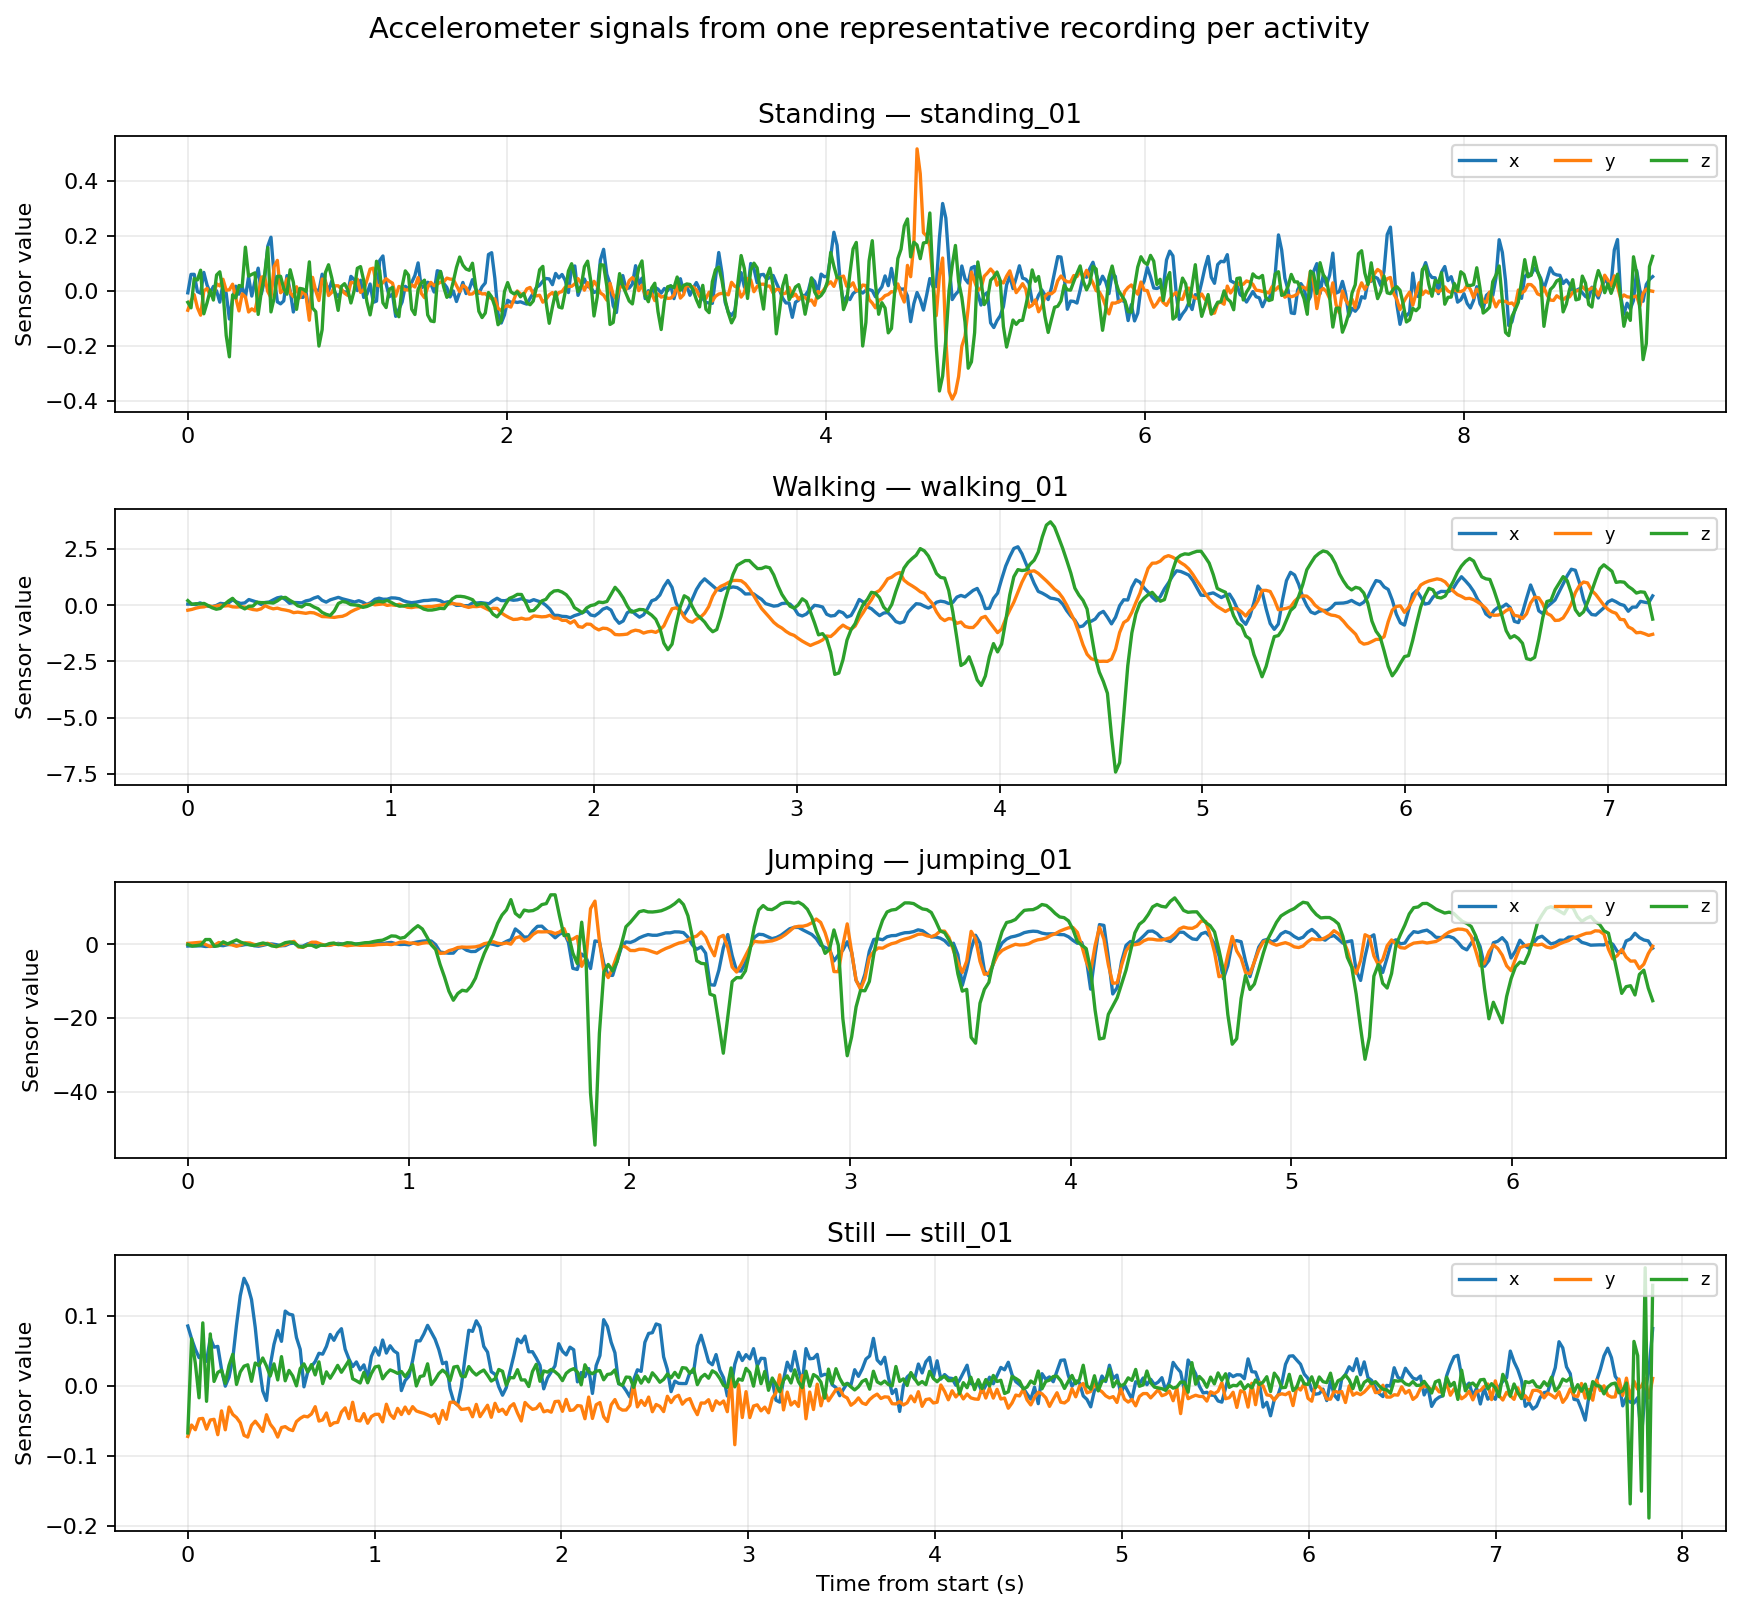

In [3]:
display(Image(filename=str(PROJECT_ROOT / 'figures' / 'sample_accelerometer_signals.png')))

## Representative Gyroscope Signals


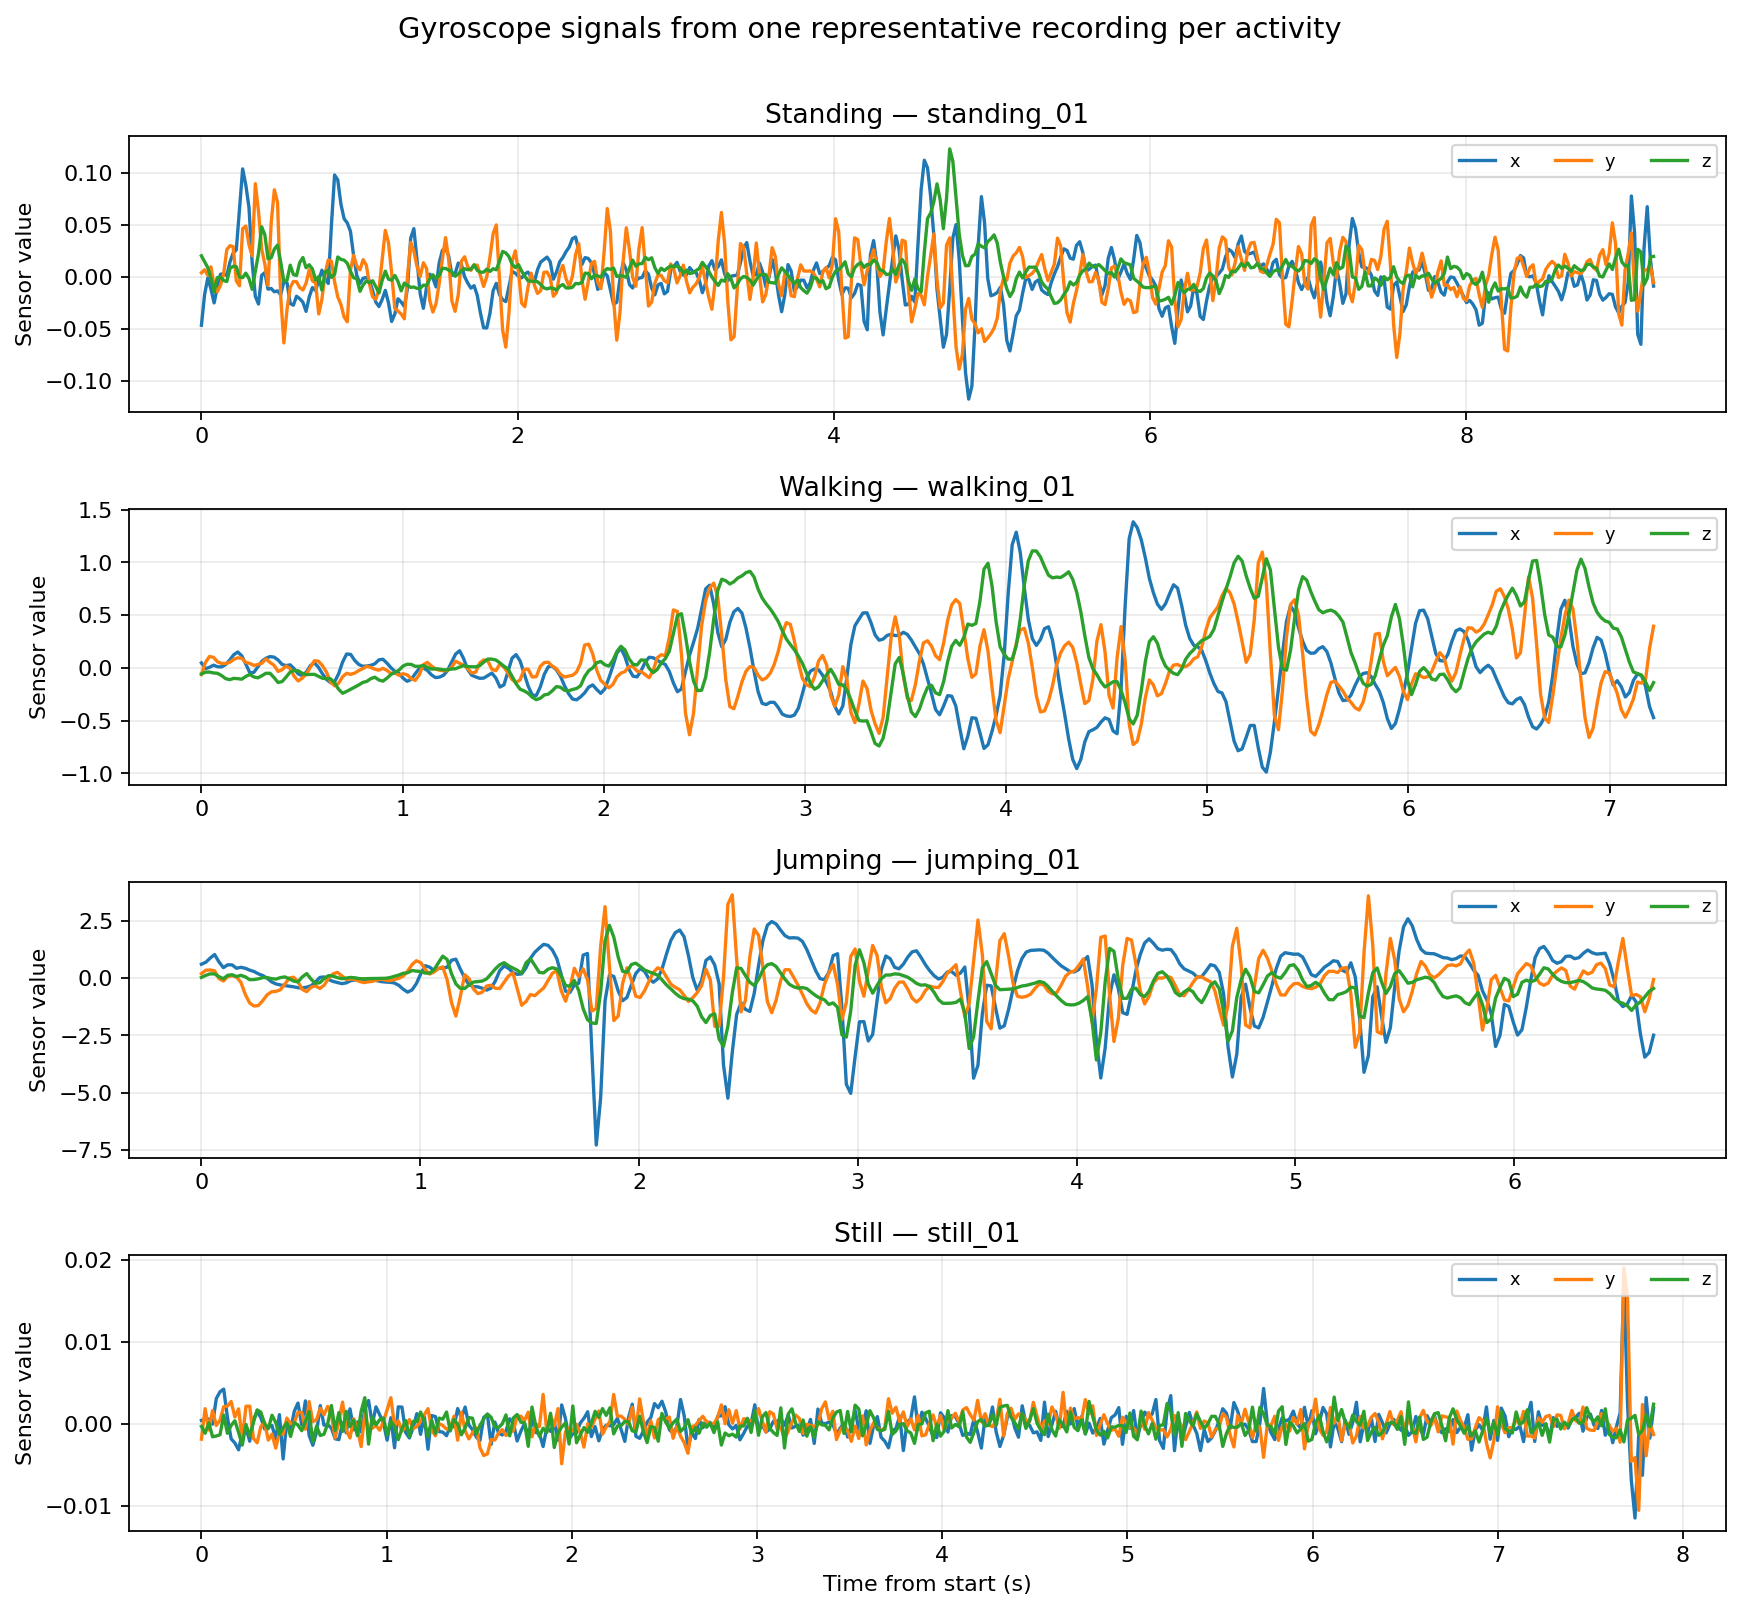

In [4]:
display(Image(filename=str(PROJECT_ROOT / 'figures' / 'sample_gyroscope_signals.png')))

## Recording Duration and Sampling-Rate Checks


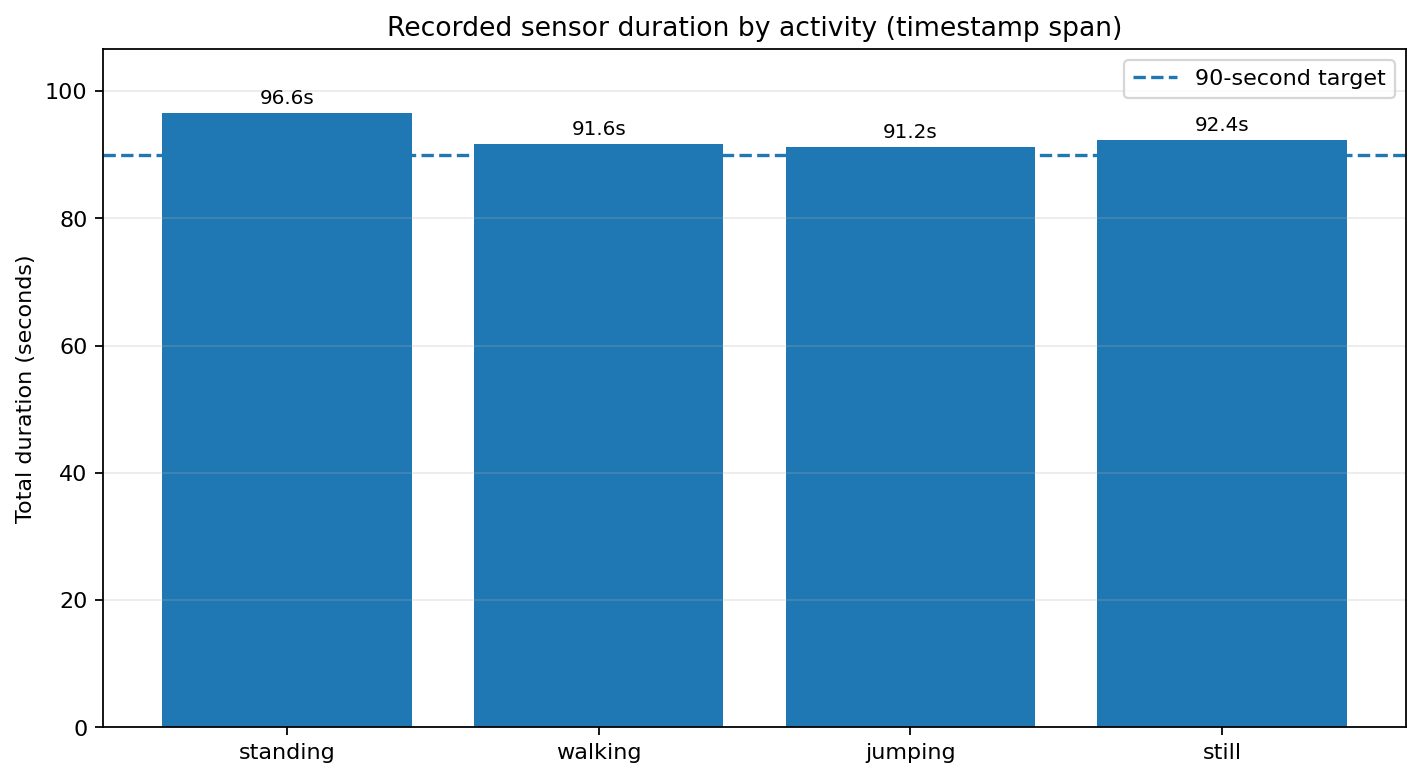

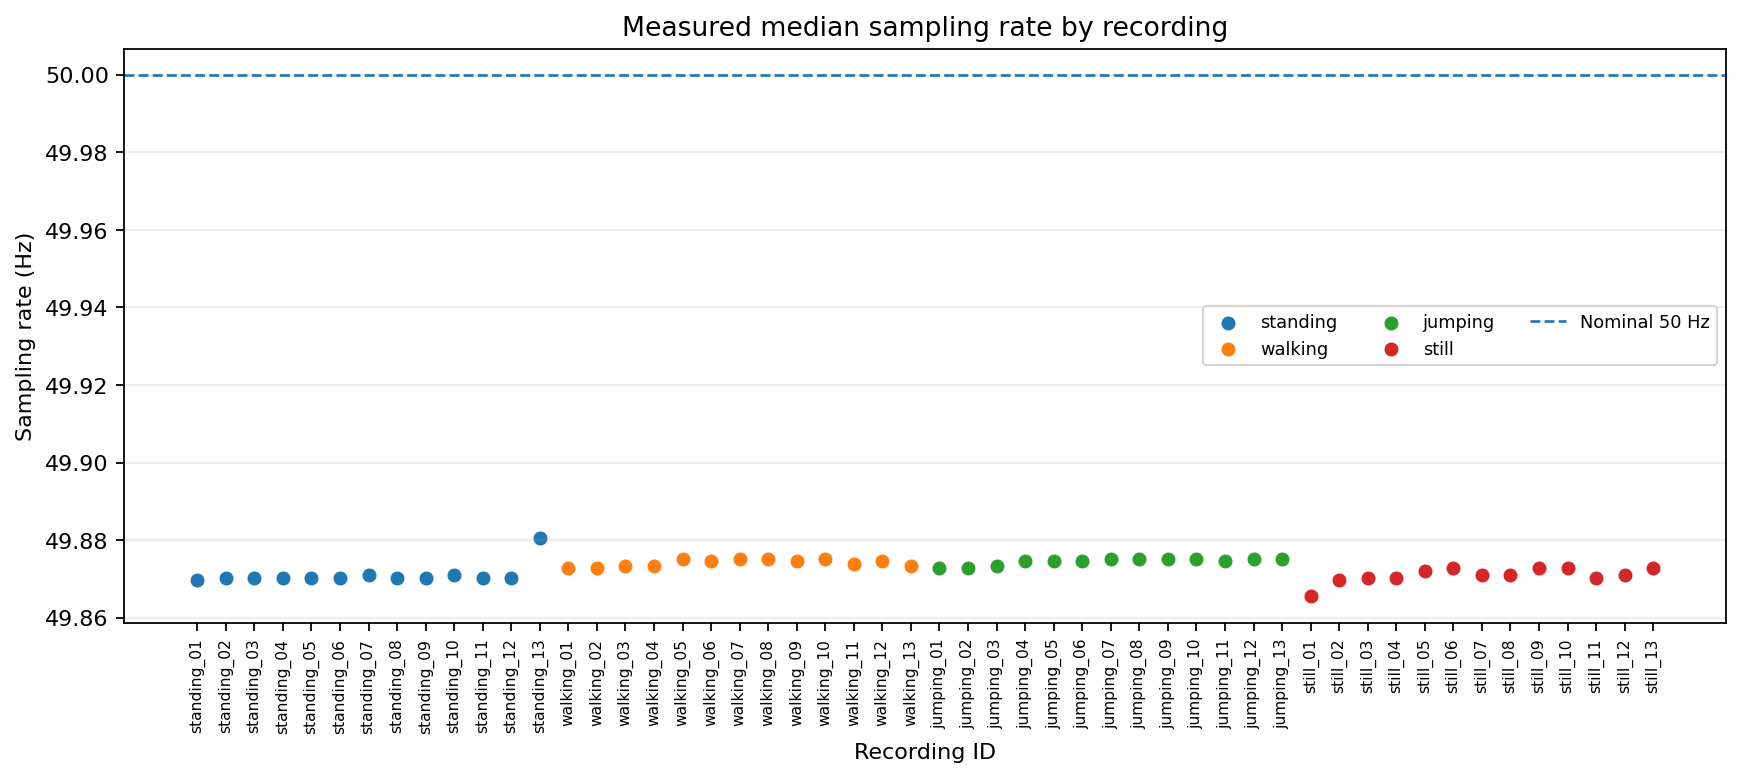

In [5]:
display(Image(filename=str(PROJECT_ROOT / 'figures' / 'activity_duration_summary.png')))
display(Image(filename=str(PROJECT_ROOT / 'figures' / 'sampling_rate_by_recording.png')))

## Train/Test Split Integrity

Every recording ID belongs to exactly one split, and the test split contains recordings from all four activities. Because the recordings come from the same participant, phone, and collection period, the evaluation measures performance on held-out recordings from this data collection; it does not establish generalization to other people or devices.


In [6]:
train_ids = set(manifest.loc[manifest.split == 'train', 'recording_id'])
test_ids = set(manifest.loc[manifest.split == 'test', 'recording_id'])
assert train_ids.isdisjoint(test_ids)
assert set(manifest.loc[manifest.split == 'test', 'activity']) == {'standing','walking','jumping','still'}
print(f'Train recordings: {len(train_ids)}; test recordings: {len(test_ids)}')
print('No recording ID appears in both splits.')

Train recordings: 44; test recordings: 8
No recording ID appears in both splits.
